In [2]:
# ==============================
# Data Handling
# ==============================
import pandas as pd
import numpy as np

# ==============================
# Encoding
# ==============================
from sklearn.preprocessing import (
    LabelEncoder,
    OneHotEncoder,
    OrdinalEncoder
)

# ==============================
# Scaling
# ==============================
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
    MaxAbsScaler,
    Normalizer
)

# ==============================
# Feature Selection
# ==============================
from sklearn.feature_selection import (
    VarianceThreshold,
    SelectKBest,
    chi2,
    mutual_info_classif,
    mutual_info_regression
)

# ==============================
# Visualization
# ==============================
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
import pandas as pd

df = pd.DataFrame({
    "Student_ID": [101,102,103,104,105,106,107,108],
    "Gender": ["Male","Female","Male","Female","Male","Female","Male","Female"],
    "City": ["Pune","Mumbai","Pune","Nashik","Mumbai","Pune","Nashik","Mumbai"],
    "Study_Hours": [2,5,6,3,8,4,7,5],
    "Attendance": [70,90,95,75,98,85,96,88],
    "Family_Income": [30000,45000,60000,35000,70000,50000,65000,55000],
    "Pass": ["No","Yes","Yes","No","Yes","Yes","Yes","Yes"]
})
df

,Student_ID,Gender,City,Study_Hours,Attendance,Family_Income,Pass
0,101,Male,Pune,2,70,30000,No
1,102,Female,Mumbai,5,90,45000,Yes
2,103,Male,Pune,6,95,60000,Yes
3,104,Female,Nashik,3,75,35000,No
4,105,Male,Mumbai,8,98,70000,Yes
5,106,Female,Pune,4,85,50000,Yes
6,107,Male,Nashik,7,96,65000,Yes
7,108,Female,Mumbai,5,88,55000,Yes


In [14]:
le = LabelEncoder()

df["Gender"] = le.fit_transform(df["Gender"])
df["Pass"] = le.fit_transform(df["Pass"])

encoder = OneHotEncoder()
encoded = encoder.fit_transform(df[["City"]])


encoded_df = pd.DataFrame(
    encoded.toarray(),
    columns = encoder.get_feature_names_out(["City"])
)
df = df.drop("City", axis=1)

final_df = pd.concat([df, encoded_df], axis=1)

print(final_df)

   Student_ID  Gender  Study_Hours  Attendance  Family_Income  Pass  \
0         101       1            2          70          30000     0   
1         102       0            5          90          45000     1   
2         103       1            6          95          60000     1   
3         104       0            3          75          35000     0   
4         105       1            8          98          70000     1   
5         106       0            4          85          50000     1   
6         107       1            7          96          65000     1   
7         108       0            5          88          55000     1   

   City_Mumbai  City_Nashik  City_Pune  
0          0.0          0.0        1.0  
1          1.0          0.0        0.0  
2          0.0          0.0        1.0  
3          0.0          1.0        0.0  
4          1.0          0.0        0.0  
5          0.0          0.0        1.0  
6          0.0          1.0        0.0  
7          1.0          0.0     

In [21]:
sd = StandardScaler()

final_df[["Family_Income"]] = sd.fit_transform(final_df[["Family_Income"]])
final_df


,Student_ID,Gender,Study_Hours,Attendance,Family_Income,Pass,City_Mumbai,City_Nashik,City_Pune
0,101,1,2,70,-1.613569,0,0.0,0.0,1.0
1,102,0,5,90,-0.474579,1,1.0,0.0,0.0
2,103,1,6,95,0.664411,1,0.0,0.0,1.0
3,104,0,3,75,-1.233905,0,0.0,1.0,0.0
4,105,1,8,98,1.423737,1,1.0,0.0,0.0
5,106,0,4,85,-0.094916,1,0.0,0.0,1.0
6,107,1,7,96,1.044074,1,0.0,1.0,0.0
7,108,0,5,88,0.284747,1,1.0,0.0,0.0


In [23]:
matrix = final_df.corr(numeric_only=True)
matrix

,Student_ID,Gender,Study_Hours,Attendance,Family_Income,Pass,City_Mumbai,City_Nashik,City_Pune
Student_ID,1.000000,-0.218218,4.374089e-01,0.430551,0.579945,0.503953,0.169031,2.519763e-01,-0.394405
Gender,-0.218218,1.000000,4.008919e-01,0.278079,0.379663,0.000000,-0.258199,0.000000e+00,0.258199
Study_Hours,0.437409,0.400892,1.000000e+00,0.962616,0.963958,0.771517,0.414039,6.852445e-17,-0.414039
Attendance,0.430551,0.278079,9.626163e-01,1.000000,0.948929,0.894486,0.400026,-9.938733e-02,-0.311132
Family_Income,0.579945,0.379663,9.639579e-01,0.948929,1.000000,0.821995,0.318593,-5.479966e-02,-0.269579
Pass,0.503953,0.000000,7.715167e-01,0.894486,0.821995,1.000000,0.447214,-3.333333e-01,-0.149071
City_Mumbai,0.169031,-0.258199,4.140393e-01,0.400026,0.318593,0.447214,1.000000,-4.472136e-01,-0.600000
City_Nashik,0.251976,0.000000,6.852445e-17,-0.099387,-0.054800,-0.333333,-0.447214,1.000000e+00,-0.447214
City_Pune,-0.394405,0.258199,-4.140393e-01,-0.311132,-0.269579,-0.149071,-0.600000,-4.472136e-01,1.000000


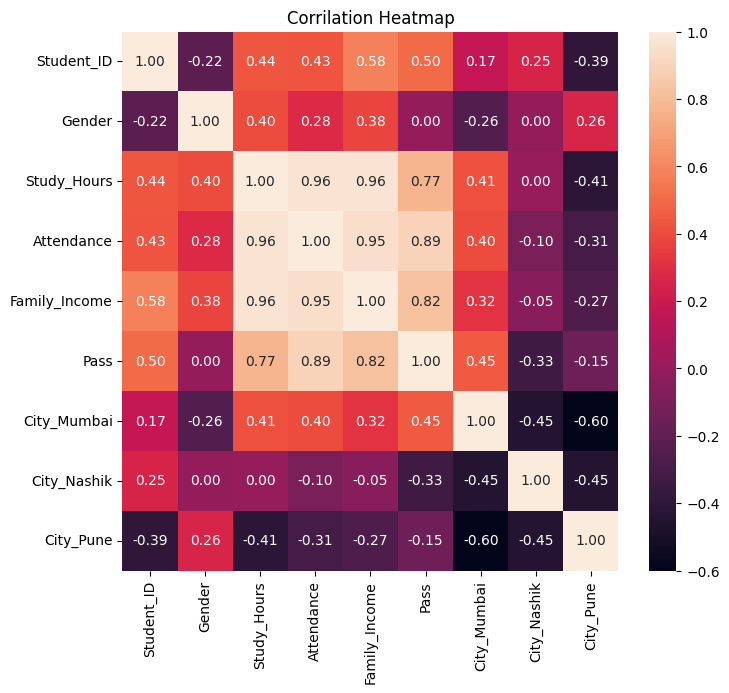

In [24]:
plt.figure(figsize=(8,7))

sns.heatmap(
    matrix,
    annot = True,
    fmt = ".2f"
)
plt.title("Corrilation Heatmap")
plt.show()

In [26]:
upper_trangle = matrix.where(
    np.triu(np.ones(matrix.shape),k=1).astype(bool)
)

upper_trangle

,Student_ID,Gender,Study_Hours,Attendance,Family_Income,Pass,City_Mumbai,City_Nashik,City_Pune
Student_ID,NaN,-0.218218,0.437409,0.430551,0.579945,0.503953,0.169031,2.519763e-01,-0.394405
Gender,NaN,NaN,0.400892,0.278079,0.379663,0.000000,-0.258199,0.000000e+00,0.258199
Study_Hours,NaN,NaN,NaN,0.962616,0.963958,0.771517,0.414039,6.852445e-17,-0.414039
Attendance,NaN,NaN,NaN,NaN,0.948929,0.894486,0.400026,-9.938733e-02,-0.311132
Family_Income,NaN,NaN,NaN,NaN,NaN,0.821995,0.318593,-5.479966e-02,-0.269579
Pass,NaN,NaN,NaN,NaN,NaN,NaN,0.447214,-3.333333e-01,-0.149071
City_Mumbai,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-4.472136e-01,-0.600000
City_Nashik,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.447214
City_Pune,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [28]:
final_feature =[
    columns
    for columns in upper_trangle
    if any(upper_trangle[columns]>0.95)
]

final_feature

['Attendance', 'Family_Income']

In [31]:
selector = VarianceThreshold(threshold=0)
x_new = selector.fit_transform(final_df)

selected_columns = final_df.columns[selector.get_support()]

new_df = pd.DataFrame(x_new,columns=selected_columns)

new_df

,Student_ID,Gender,Study_Hours,Attendance,Family_Income,Pass,City_Mumbai,City_Nashik,City_Pune
0,101.0,1.0,2.0,70.0,-1.613569,0.0,0.0,0.0,1.0
1,102.0,0.0,5.0,90.0,-0.474579,1.0,1.0,0.0,0.0
2,103.0,1.0,6.0,95.0,0.664411,1.0,0.0,0.0,1.0
3,104.0,0.0,3.0,75.0,-1.233905,0.0,0.0,1.0,0.0
4,105.0,1.0,8.0,98.0,1.423737,1.0,1.0,0.0,0.0
5,106.0,0.0,4.0,85.0,-0.094916,1.0,0.0,0.0,1.0
6,107.0,1.0,7.0,96.0,1.044074,1.0,0.0,1.0,0.0
7,108.0,0.0,5.0,88.0,0.284747,1.0,1.0,0.0,0.0
